First we load the necessary libraries

In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import warnings
from cartopy.io import DownloadWarning

#just so we dont get a warnings
warnings.filterwarnings("ignore", category=DownloadWarning)
pypsa.options.api.legacy_string_dtype = True 

#### TASK 1 : Network Optimization and Generator Dispatch Analysis. 

We take the meshed AC-DC network example from PyPSA and modify it to keep the Norwich converter capacity fixed.

In [2]:
# Loading the AC-DC meshed network
m_net = pypsa.examples.ac_dc_meshed()

# Setting the p_nom_extendable attribute of the link "Norwich Converter" to False
m_net.links.loc["Norwich Converter", "p_nom_extendable"] = False

print(m_net)

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


PyPSA Network 'AC-DC-Meshed'


Let's visualize the geographical layout of our model

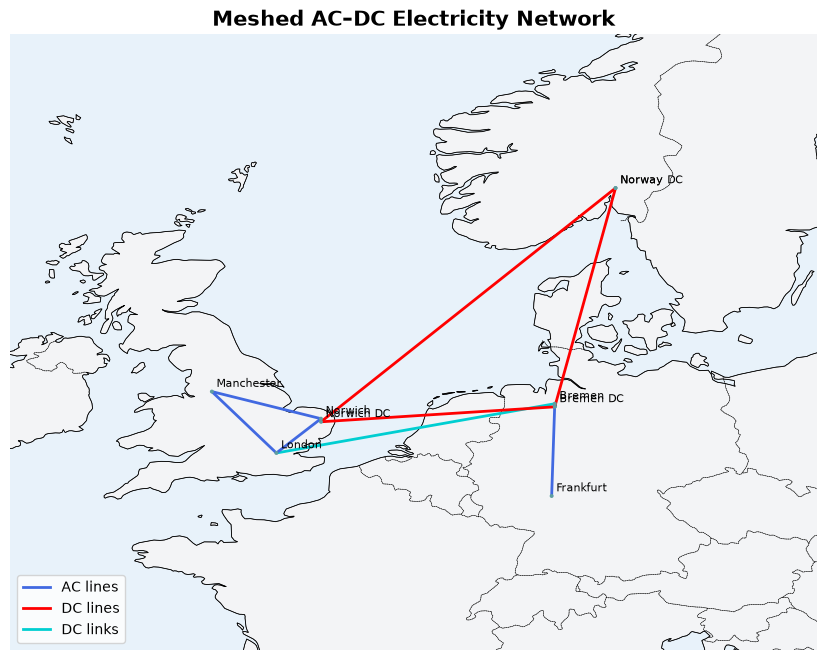

In [3]:
# Identifying the AC and DC transmission lines
line_colors = m_net.lines.bus0.map(
    m_net.buses.carrier
).map(lambda carrier: "red" if carrier == "DC" else "royalblue")

fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Geographic background
ax.add_feature(cfeature.LAND, facecolor="#f3f4f6")
ax.add_feature(cfeature.OCEAN, facecolor="#e8f2fa")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)

# Draw the network
m_net.plot(
    ax=ax,
    line_colors=line_colors,
    link_colors="darkturquoise",
    bus_sizes=0.004,
    line_widths=2,
    link_widths=2,
    margin=0.5
)

# Label buses
for bus, data in m_net.buses.iterrows():
    ax.text(
        data.x + 0.15,
        data.y + 0.15,
        bus,
        fontsize=8,
        transform=ccrs.PlateCarree()
    )

ax.set_title(
    "Meshed AC–DC Electricity Network",
    fontsize=15,
    weight="bold"
)

legend_elements = [
    Line2D([0], [0], color="royalblue", lw=2, label="AC lines"),
    Line2D([0], [0], color="red", lw=2, label="DC lines"),
    Line2D([0], [0], color="darkturquoise", lw=2, label="DC links")
]

ax.legend(handles=legend_elements, loc="lower left")

plt.savefig(
    "../plots/ac_dc_network_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The network map above illustrates the geographical distribution of buses and transmission interconnections the model. AC lines, DC lines, and converter links are distinguished to show how electricity can be transferred between locations. These interconnections allow generation in one area to serve demand elsewhere, although transmission capacities and network constraints can influence dispatch and locational electricity prices.

Lets inspect the generators in the network to see their attributes, including whether they are extendable or not.

In [4]:
generator_info = m_net.generators[
    ["bus", "carrier", "p_nom", "p_nom_extendable",
     "p_nom_min", "capital_cost", "marginal_cost"]
]

display(generator_info)

,bus,carrier,p_nom,p_nom_extendable,p_nom_min,capital_cost,marginal_cost
name,,,,,,,
Manchester Wind,Manchester,wind,80.0,True,100.0,2793.651603,0.110000
Manchester Gas,Manchester,gas,50000.0,True,0.0,196.615168,4.532368
Norway Wind,Norway,wind,100.0,True,100.0,2184.374796,0.090000
Norway Gas,Norway,gas,20000.0,True,0.0,158.251250,5.892845
Frankfurt Wind,Frankfurt,wind,110.0,True,100.0,2129.456122,0.100000
Frankfurt Gas,Frankfurt,gas,80000.0,True,0.0,102.676953,4.086322


All Gas based generators have very large nominal capacities than the renewables. We can see that they also have very small capital cost and a very high marginal cost. Frankfurt has both the lowest capital cost and the lowest marginal generation cost among them.  Economicaly speaking, they are primarily not meant to be used in the optimal dispatch of the network, but rather as a backup for when renewable generation is not sufficient to meet demand. We will assess it further after running the dispatch optimization.

We examine electricity demand in the network.

In [5]:
# Print the load information in the network
display(m_net.loads)

# Print the active power demand (p_set) of the loads in the network
display(m_net.loads_t.p_set)

,bus,carrier,type,p_set,q_set,sign,active
name,,,,,,,
London,London,load,,0.0,0.0,-1.0,True
Frankfurt,Frankfurt,load,,0.0,0.0,-1.0,True
Norway,Norway,load,,0.0,0.0,-1.0,True
Norwich,Norwich,load,,0.0,0.0,-1.0,True
Bremen,Bremen,load,,0.0,0.0,-1.0,True
Manchester,Manchester,load,,0.0,0.0,-1.0,True


name,London,Norwich,Frankfurt,Bremen,Norway,Manchester
snapshot,,,,,,
2015-01-01 00:00:00,35.796244,415.462564,398.047847,640.086378,820.035836,857.551440
2015-01-01 01:00:00,976.824561,262.606146,432.436106,703.554334,854.834047,750.599624
2015-01-01 02:00:00,250.587312,418.476353,379.803928,440.836130,42.550744,156.564876
2015-01-01 03:00:00,130.753145,552.959539,868.361764,612.576306,647.548233,527.870822
2015-01-01 04:00:00,151.100169,218.159858,548.770755,803.436781,884.073873,83.897759
2015-01-01 05:00:00,931.857052,791.976266,828.665243,605.400687,509.062449,676.623319
2015-01-01 06:00:00,289.848287,531.870681,449.290752,641.090590,595.607965,731.137100
2015-01-01 07:00:00,864.343322,23.513467,699.163766,408.008541,291.642450,553.344889
2015-01-01 08:00:00,689.577264,970.059068,915.866780,912.247776,2.153493,298.338082


We run the optimization using the "highs" solver.

In [6]:
status, condition = m_net.optimize(solver_name="highs")

/tmp/ipykernel_83098/337597941.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = m_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.16s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -3.47e+06
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lowe

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-g6p1v06l has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [1e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [9e-01, 1e+03]
Presolving model
371 rows, 186 cols, 890 nonzeros 0s
284 rows, 99 cols, 932 nonzeros 0s
Dependent equations search running on 23 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
284 rows, 99 cols, 932 nonzeros 0s
Presolve reductions: rows 284(-183); columns 99(-88); nonzeros 932(-54) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1204315698e+07 Pr: 110(102101); Du: 0(1.47519e-11) 0.0s
        119    -3.4740941308e+06 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the s

In [7]:
# We verify that the optimization was successful

print("Status:", status)
print("Termination condition:", condition)

Status: ok
Termination condition: optimal


Lets examine the optimized generator capacity

In [8]:
optimized_capacity = (
    m_net.generators[["bus", "p_nom", "p_nom_opt"]]
    .sort_values("p_nom_opt", ascending=False)
)

display(optimized_capacity.round(2))

,bus,p_nom,p_nom_opt
name,,,
Manchester Wind,Manchester,80.0,4090.81
Frankfurt Wind,Frankfurt,110.0,1667.72
Norway Wind,Norway,100.0,1533.60
Frankfurt Gas,Frankfurt,80000.0,982.03
Manchester Gas,Manchester,50000.0,0.00
Norway Gas,Norway,20000.0,0.00


How much electricity is generated by each generator at 5:00 AM on January 1, 2015?

In [9]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

dispatch_0500 = m_net.generators_t.p.loc[snapshot]

display(dispatch_0500.sort_values(ascending=False).round(2))

name
Manchester Wind    2469.21
Frankfurt Gas       982.03
Frankfurt Wind      877.48
Norway Wind          14.86
Manchester Gas       -0.00
Norway Gas           -0.00
Name: 2015-01-01 05:00:00, dtype: float64

At 05:00, the optimized model dispatches wind generation from Manchester, Franfurt, and Norway, with Frankfurt Gas being the only fossil-fuel generator operating. Wind generation is prioritized because of its lower marginal cost, while Frankfurt Gas supplies the remaining electricity demand. However, Norway Wind contributes only 14.86 MW, despite having a lower marginal cost than Frankfurt Gas. This suggests that its dispatch may be constrained by wind availability rather than generation cost. Frankfurt Gas also operates at its full optimized capcity of 982.03 MW. To understand this dispatch pattern, lets examine wind availability, generator costs, and locational marginal prices.

In [10]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

# Wind availability and actual generation
wind_generators = m_net.generators.index[
    m_net.generators.carrier == "wind"
]

wind_analysis = pd.DataFrame({
    "Installed capacity (MW)": m_net.generators.loc[
        wind_generators, "p_nom_opt"
    ],
    "Availability factor": m_net.generators_t.p_max_pu.loc[
        snapshot, wind_generators
    ],
    "Actual dispatch (MW)": m_net.generators_t.p.loc[
        snapshot, wind_generators
    ]
})

wind_analysis["Available generation (MW)"] = (
    wind_analysis["Installed capacity (MW)"]
    * wind_analysis["Availability factor"]
)

display(wind_analysis.round(2))

,Installed capacity (MW),Availability factor,Actual dispatch (MW),Available generation (MW)
name,,,,
Manchester Wind,4090.81,0.60,2469.21,2469.21
Norway Wind,1533.60,0.01,14.86,14.86
Frankfurt Wind,1667.72,0.53,877.48,877.48


It is clear that the actual dispatch of the wind generators is limited by their availability factor and that availability varies substantially across locations. Manchester wind and Frankfurt Wind operate at approximately 60% and 53% of their installed capacities, respectively, whereas Norway Wind has an availability factor of only about 1% at 5 oclock. All of three wind generators dispatch their full available output. This means that no wind energy is curtailed at this hour.

In [11]:
# Locational marginal prices of electricity prices at 05:00
prices_0500 = m_net.buses_t.marginal_price.loc[snapshot]

display(prices_0500.round(2))

name
London        1593.66
Norwich       1593.66
Norwich DC    1593.66
Manchester    1593.66
Bremen        1593.66
Bremen DC     1593.66
Frankfurt     1593.46
Norway        1593.66
Norway DC     1593.66
Name: 2015-01-01 05:00:00, dtype: float64

The LMPs are nearly identical across the network, ranging from approximately €1,593.46/MWh in Frankfurt to €1,593.66/MWh in other locations. This dispatch is consistent with cost-minimizing generation under variable wind availability.

In [12]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

# Generator information
hourly_merit = m_net.generators[
    ["carrier", "marginal_cost", "p_nom_opt"]
].copy()

# Wind availability at the selected hour
hourly_merit["availability"] = 1.0

wind_units = hourly_merit.index[
    hourly_merit["carrier"] == "wind"
]

hourly_merit.loc[wind_units, "availability"] = (
    m_net.generators_t.p_max_pu.loc[snapshot, wind_units]
)

# Available capacity
hourly_merit["available_mw"] = (
    hourly_merit["p_nom_opt"] * hourly_merit["availability"]
)

# Sort generators by marginal cost
hourly_merit = hourly_merit.sort_values("marginal_cost")

# Starting position of each generator block
hourly_merit["start_mw"] = (
    hourly_merit["available_mw"].cumsum()
    - hourly_merit["available_mw"]
)

display(hourly_merit.round(2))

,carrier,marginal_cost,p_nom_opt,availability,available_mw,start_mw
name,,,,,,
Norway Wind,wind,0.09,1533.60,0.01,14.86,0.00
Frankfurt Wind,wind,0.10,1667.72,0.53,877.48,14.86
Manchester Wind,wind,0.11,4090.81,0.60,2469.21,892.34
Frankfurt Gas,gas,4.09,982.03,1.00,982.03,3361.55
Manchester Gas,gas,4.53,0.00,1.00,0.00,4343.59
Norway Gas,gas,5.89,0.00,1.00,0.00,4343.59


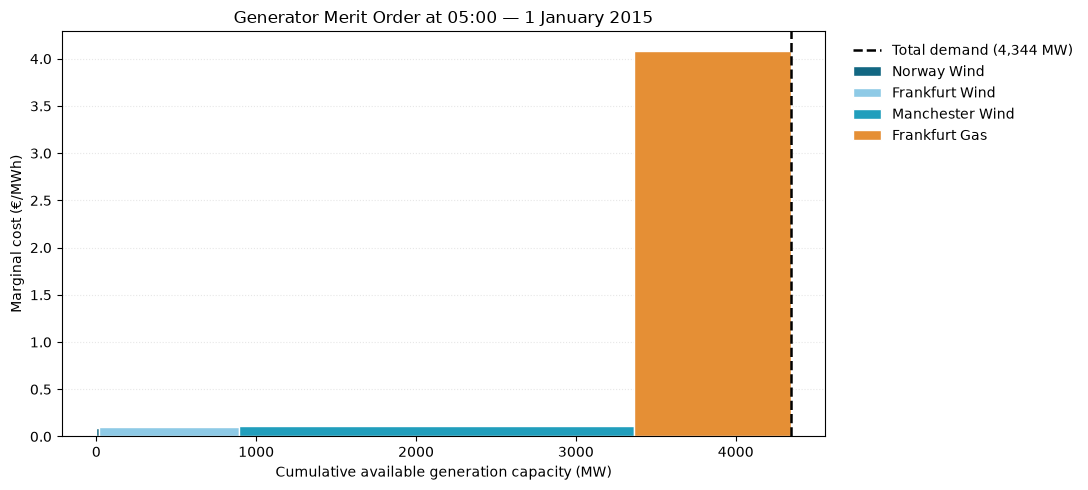

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))

generator_colors = {
    "Norway Wind": "#126782",
    "Frankfurt Wind": "#8ECAE6",
    "Manchester Wind":"#219EBC",
    "Frankfurt Gas": "#E58F35",
    "Manchester Gas": "#F4B183",
    "Norway Gas": "#C65D3B"
}

for generator, row in hourly_merit.iterrows():
    if row["available_mw"] <= 0:
        continue

    ax.bar(
        row["start_mw"],
        row["marginal_cost"],
        width=row["available_mw"],
        align="edge",
        color=generator_colors[generator],
        edgecolor="white",
        linewidth=1,
        label=generator
    )

# Total electricity demand at 05:00
demand_0500 = m_net.loads_t.p_set.loc[snapshot].sum()

ax.axvline(
    demand_0500,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Total demand ({demand_0500:,.0f} MW)"
)

ax.set_xlabel("Cumulative available generation capacity (MW)")
ax.set_ylabel("Marginal cost (€/MWh)")
ax.set_title("Generator Merit Order at 05:00 — 1 January 2015")

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis="y", linestyle=":", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../plots/merit_order_0500.png", dpi=300, bbox_inches="tight")
plt.show()

The figure above illustrates the merit order of generators at 05:00 on 1 January 2015. Wind generators are at the lower end of the supply curve due to their relatively lower marginal cost of production. However ther capacity are contrained by the weather. Total available wind generation is approximately 3,362 MW whilst the electricity demand is 4,344 MW. The resulting supply shortfall of approximately 982 MW is then met by Frankfurt Gas, which operates at its full optimized capacity. As discussed earlier on in task 1, Frankfurt Gas has the lowest capital and marginal costs among the three gas generators. The optimization therefore selects Frankfurt Gas rather than Manchester Gas or Norway Gas in cost-efficiency dispatch.

#### TASK 2: Electricity Generation, Wind Curtailment, and Energy Storage

We first plot the dispatch of individual generators against total electricity demand to see how generation changes over time and when gas is needed to support wind generation.

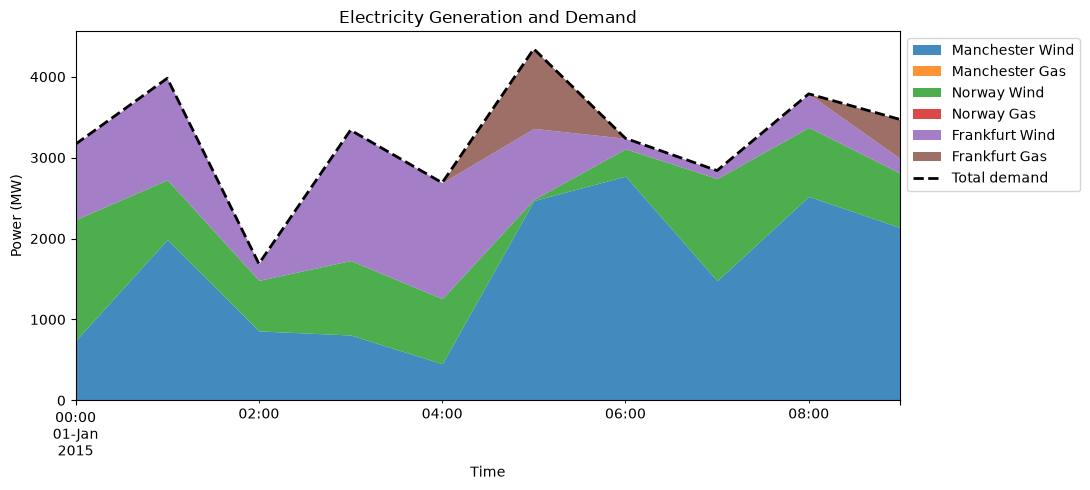

In [14]:
# Lets get the hourly generation dispatch and total electricity demand
generator_dispatch = m_net.generators_t.p
total_demand = m_net.loads_t.p_set.sum(axis=1)

# Plotting generation from each generator as a stacked area chart
ax = generator_dispatch.plot.area(
    stacked=True,
    figsize=(11, 5),
    linewidth=0,
    alpha=0.85
)

# Adding total demand as a dashed line for comparison
total_demand.plot(
    ax=ax,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Total demand"
)

ax.set_title("Electricity Generation and Demand")
ax.set_xlabel("Time")
ax.set_ylabel("Power (MW)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()

# Saving the figure
plt.savefig("../plots/generation_and_demand.png", dpi=300, bbox_inches="tight")
plt.show()

From the plot above, Frankfurt Gas operates only at 05:00 and 09:00, when wind generation is insufficient to meet electricity demand. This illustrates the importance of dispatchable backup generation in systems with variable renewable energy. A related real-world example is *Dunkelflaute*, a term used in Germany to describe prolonged periods of low wind and solar generation, during which flexible generation, energy storage, or electricity imports may be needed to maintain supply-demand balance.

Now lets check Frankfurt Gas dispatching across all the snapshots to clatrify the exact hours when it was needed.

In [15]:
# Check when Frankfurt Gas generates electricity ie. time and amount of electricity generated
m_net.generators_t.p["Frankfurt Gas"].round(2)

snapshot
2015-01-01 00:00:00     -0.00
2015-01-01 01:00:00     -0.00
2015-01-01 02:00:00     -0.00
2015-01-01 03:00:00     -0.00
2015-01-01 04:00:00     -0.00
2015-01-01 05:00:00    982.03
2015-01-01 06:00:00     -0.00
2015-01-01 07:00:00     -0.00
2015-01-01 08:00:00     -0.00
2015-01-01 09:00:00    483.24
Name: Frankfurt Gas, dtype: float64

Having identified 05:00 and 09:00 as the hours when Frankfurt Gas operates, we compare available wind generation with demand to understand why gas is needed.

In [16]:
# Lets select the two hours when Frankfurt Gas operates
hours = pd.to_datetime([
    "2015-01-01 05:00:00",
    "2015-01-01 09:00:00"
])

# Identify the wind generators
wind_units = m_net.generators.index[
    m_net.generators.carrier == "wind"
]

# Calculate available wind generation using optimized capacities
wind_available = (
    m_net.generators_t.p_max_pu[wind_units]
    * m_net.generators.loc[wind_units, "p_nom_opt"]
)

# Get actual wind dispatch
wind_dispatch = m_net.generators_t.p[wind_units]

# Comparing demand, available wind and gas generation
dispatch_comparison = pd.DataFrame({
    "Demand (MW)": m_net.loads_t.p_set.loc[hours].sum(axis=1),
    "Available wind (MW)": wind_available.loc[hours].sum(axis=1),
    "Wind dispatch (MW)": wind_dispatch.loc[hours].sum(axis=1),
    "Frankfurt Gas (MW)": m_net.generators_t.p.loc[hours, "Frankfurt Gas"]
})

# Calculate the gap between demand and available wind
dispatch_comparison["Wind shortfall (MW)"] = (
    dispatch_comparison["Demand (MW)"]
    - dispatch_comparison["Available wind (MW)"]
)

display(dispatch_comparison.round(2))

,Demand (MW),Available wind (MW),Wind dispatch (MW),Frankfurt Gas (MW),Wind shortfall (MW)
snapshot,,,,,
2015-01-01 05:00:00,4343.59,3361.55,3361.55,982.03,982.03
2015-01-01 09:00:00,3470.78,2987.54,2987.54,483.24,483.24


We can conclude from The table and pot above that wind supplies most electricity demand, while Frankfurt Gas operates mainly at 05:00 and 09:00, when available wind generation is insufficient to meet demand. Next, we calculate the difference between available wind generation and actual wind dispatch. This helps identify when and where wind energy is curttailed.

In [17]:
# Wind curtailment by taking away the dispatched wind from the available wind generation, and clipping negative values to zero
wind_curtailment = (
    wind_available - wind_dispatch # these are are already defined above
).clip(lower=0)

# Total curtailed wind generation at each snapshot by summing the curtailment across all wind generators
total_curtailment = wind_curtailment.sum(axis=1)

curtailment_summary = pd.DataFrame({
    "Available wind (MW)": wind_available.sum(axis=1),
    "Dispatched wind (MW)": wind_dispatch.sum(axis=1),
    "Curtailment (MW)": total_curtailment
})

display(curtailment_summary.round(2))

,Available wind (MW),Dispatched wind (MW),Curtailment (MW)
snapshot,,,
2015-01-01 00:00:00,6231.54,3166.98,3064.56
2015-01-01 01:00:00,3980.85,3980.85,0.00
2015-01-01 02:00:00,1786.42,1688.82,97.60
2015-01-01 03:00:00,3586.07,3340.07,246.00
2015-01-01 04:00:00,4801.46,2689.44,2112.02
2015-01-01 05:00:00,3361.55,3361.55,0.00
2015-01-01 06:00:00,3245.27,3238.85,6.43
2015-01-01 07:00:00,2840.02,2840.02,0.00
2015-01-01 08:00:00,3810.42,3788.24,22.18


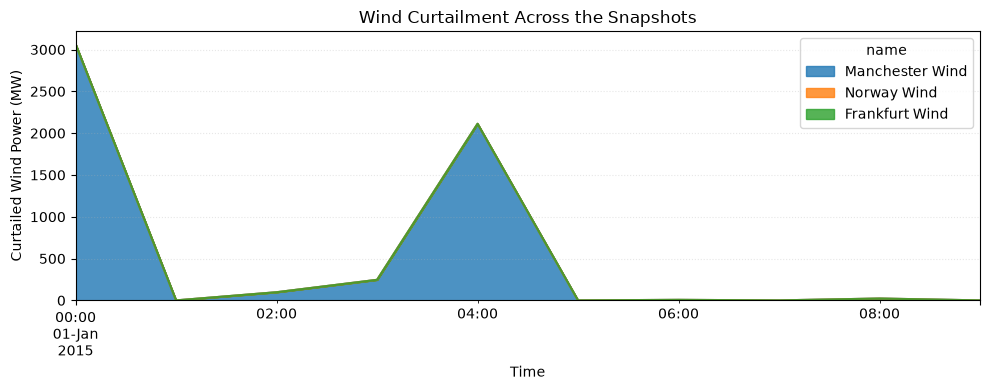

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))

wind_curtailment.plot.area(
    ax=ax,
    stacked=True,
    alpha=0.8
)

ax.set_title("Wind Curtailment Across the Snapshots")
ax.set_xlabel("Time")
ax.set_ylabel("Curtailed Wind Power (MW)")

ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.savefig("../plots/wind_curtailment.png", dpi=300, bbox_inches="tight")
plt.show()

Wind curtailment occurs at several snapshots but most notably at 00:00 (3,064.56 MW) and 04:00 (2,112.02 MW), predominantly from Manchester Wind. In real electricity markets, curtailment can arise from excess renewable generation, low electricity demand, transmission congestion, or real-time imbalances between scheduled and actual generation and consumption (Creti & Fontini). Negative electricity prices can also encourage generators to reduce output when continued production becomes uneconomic.

Battery storage could absorb surplus wind electricity during periods of curtailment and discharge during periods of insufficient wind supply, such as 05:00 and 09:00 in this model. Alternatively, electrolyzers could convert surplus electricity into hydrogen for storage and later use. These options could improve renewable energy utilization and potentially reduce reliance on gas generation.

Grid expansion, the removal of transmission bottlenecks, and improved cross-border electricity trade could also help reduce curtailment by allowing surplus electricity to reach areas with higher demand (Wang & Noel, 2024). Sector coupling through electric boilers, heat pumps and thermal storage could provide additional flexibility by converting surplus renewable electricity into useful heat. Hydropower flexibility is another important consideration in European energy-system modelling (Kiehle et al., 2026).

#### TASK 3: Single-Node Optimization and Wind–Gas Investment Cost Sensitivity. At this stage, we modify the network, solve the new model, and then determine the capital-cost threhold at which Norway Wind replaces Frankfurt Gas.

We first create the single-node network

In [19]:
# Load the original example
single_net = pypsa.examples.ac_dc_meshed()

single_net.links.loc[
    "Norwich Converter", "p_nom_extendable"
] = False

# Connecting all generators and loads to Frankfurt
single_net.generators["bus"] = "Frankfurt"
single_net.loads["bus"] = "Frankfurt"

# Making sure Norway Wind is fully available at every snapshot
single_net.generators_t.p_max_pu.loc[:, "Norway Wind"] = 1.0

# setting these wind capacities to zero
single_net.generators.loc[
    ["Manchester Wind", "Frankfurt Wind"], "p_nom_min"
] = 0.0

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


In [20]:
#Lets print nicely and review the generator and load buses, Norway Wind availability, and wind minimum capacities
print("Generator buses:")
display(single_net.generators["bus"])

print("Load buses:")
display(single_net.loads["bus"])

print("Norway Wind availability:")
display(single_net.generators_t.p_max_pu["Norway Wind"])

print("Wind minimum capacities:")
display(
    single_net.generators.loc[
        ["Manchester Wind", "Frankfurt Wind"],
        ["p_nom_min"]
    ]
)

Generator buses:


name
Manchester Wind    Frankfurt
Manchester Gas     Frankfurt
Norway Wind        Frankfurt
Norway Gas         Frankfurt
Frankfurt Wind     Frankfurt
Frankfurt Gas      Frankfurt
Name: bus, dtype: str

Load buses:


name
London        Frankfurt
Frankfurt     Frankfurt
Norway        Frankfurt
Norwich       Frankfurt
Bremen        Frankfurt
Manchester    Frankfurt
Name: bus, dtype: str

Norway Wind availability:


snapshot
2015-01-01 00:00:00    1.0
2015-01-01 01:00:00    1.0
2015-01-01 02:00:00    1.0
2015-01-01 03:00:00    1.0
2015-01-01 04:00:00    1.0
2015-01-01 05:00:00    1.0
2015-01-01 06:00:00    1.0
2015-01-01 07:00:00    1.0
2015-01-01 08:00:00    1.0
2015-01-01 09:00:00    1.0
Name: Norway Wind, dtype: float64

Wind minimum capacities:


,p_nom_min
name,
Manchester Wind,0.0
Frankfurt Wind,0.0


From the output, wee can confirm that every generator and load is attached to Frankfurt, Norway Wind has an availability factor of 1 at all ten snapshots, and both wind generators have zero minimumm capacity.

Now we perform our Optimization on the modified network

In [21]:
status, condition = single_net.optimize(solver_name="highs")

print(f"Optimization: {status} ({condition})")

/tmp/ipykernel_83098/1955427176.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = single_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.11s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -1.41e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-u5anmf3k has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696628574e+07 Pr: 90(71750.5) 0.0s
         45    -1.4072067755e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

Lets display and then inspect the optimized capacity

In [22]:
optimized_capacity = single_net.generators[
    ["carrier", "capital_cost", "p_nom_opt"]
].sort_values("p_nom_opt", ascending=False)

display(optimized_capacity.round(2))

,carrier,capital_cost,p_nom_opt
name,,,
Norway Wind,wind,2184.37,3549.14
Frankfurt Gas,gas,102.68,794.45
Manchester Gas,gas,196.62,0.00
Manchester Wind,wind,2793.65,0.00
Norway Gas,gas,158.25,0.00
Frankfurt Wind,wind,2129.46,0.00


Lets also examine the dispatch

In [23]:
display(single_net.generators_t.p.round(2))

name,Manchester Wind,Manchester Gas,Norway Wind,Norway Gas,Frankfurt Wind,Frankfurt Gas
snapshot,,,,,,
2015-01-01 00:00:00,-0.0,-0.0,3166.98,-0.0,-0.0,-0.00
2015-01-01 01:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,431.72
2015-01-01 02:00:00,-0.0,-0.0,1688.82,-0.0,-0.0,-0.00
2015-01-01 03:00:00,-0.0,-0.0,3340.07,-0.0,-0.0,-0.00
2015-01-01 04:00:00,-0.0,-0.0,2689.44,-0.0,-0.0,-0.00
2015-01-01 05:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,794.45
2015-01-01 06:00:00,-0.0,-0.0,3238.85,-0.0,-0.0,-0.00
2015-01-01 07:00:00,-0.0,-0.0,2840.02,-0.0,-0.0,-0.00
2015-01-01 08:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,239.11


From the single-node model table above, we see that Norway Wind supplies most of the electricity, but Frankfurt Gas remains necessary during three hours (1, 5 and 8 oclock).

Now is the capital-cost sensitivity analysis. The aim is to test Norway Wind capital costs on both sides of the expected threshold, using a fresh copy of the modified network each time. By re-optimizing the network at each cost, we can then identify the exact capital cost where additional wind capacity begin replacing gas genration.

In [24]:
# Remove the attached solver model so the network can be copied
single_net.model.solver_model = None

# Test different Norway Wind capital costs around the switching threshold then narrow down close to the threshold value
# The capital cost is 2184.37, however, we will test around the range of 100 to 200 to see how the investment decisions change
# cost_values = [200, 190, 180, 170, 160, 150, 140, 135, 130, 125, 120, 115, 110, 105, 100]
# we find out it was between 114 and 115, so we will test around that range 

cost_values = [120,115, 114.9, 114.7, 114.5, 114, 113, 110,105]

results = []

for cost in cost_values:
    # Work with a copy to preserve the original network
    test_net = single_net.copy()

    # Change Norway Wind's investment cost
    test_net.generators.loc["Norway Wind", "capital_cost"] = cost

    # Solve the network for each cost
    status, condition = test_net.optimize(solver_name="highs")

    if status == "ok" and condition == "optimal":

        # Adjusted here means I added back PyPSA's objective constant to get the total modelled costs
        adjusted_cost = (
            test_net.objective + test_net.objective_constant
        )

        # Record the investment decisions and adjusted cost
        results.append({
            "Norway Wind capital cost": cost,
            "Norway Wind (MW)": test_net.generators.loc["Norway Wind", "p_nom_opt"],
            "Frankfurt Gas (MW)": test_net.generators.loc["Frankfurt Gas", "p_nom_opt"],
            "Adjusted system cost": adjusted_cost
        })

# Compare the results across different investment costs
cost_results = pd.DataFrame(results)

display(cost_results.round(2))

/tmp/ipykernel_83098/732841329.py:21: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = test_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.11s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-z1_isdxq has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629959e+07 Pr: 90(71750.5) 0.0s
         43    -2.1192377120e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

/tmp/ipykernel_83098/732841329.py:21: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = test_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.11s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-g7pkm5zx has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629962e+07 Pr: 90(71750.5) 0.0s
         43    -2.1209622800e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.1s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.
/tmp/ipykernel_83098/732841329.py:21: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning 

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-prmv9yxy has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629962e+07 Pr: 90(71750.5) 0.0s
         43    -2.1209967714e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

... (9 outputs left out)

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-gbw1_p7_ has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629965e+07 Pr: 90(71750.5) 0.0s
         45    -2.1228113104e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.1s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.


Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-hqc612du has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629969e+07 Pr: 90(71750.5) 0.0s
         47    -2.1248124326e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

,Norway Wind capital cost,Norway Wind (MW),Frankfurt Gas (MW),Adjusted system cost
0,120.0,3549.14,794.45,516252.92
1,115.0,3549.14,794.45,498507.24
2,114.9,3549.14,794.45,498152.33
3,114.7,3549.14,794.45,497442.50
4,114.5,3788.24,555.34,496693.00
5,114.0,3788.24,555.34,494798.88
6,113.0,3788.24,555.34,491010.63
7,110.0,3980.85,362.73,479516.93
8,105.0,4343.59,0.00,459005.71


We see from the optimized results that Norway Wind capacity remains at 3,549.14 MW when its capital cost is 114.7 or higher, while Frankfurt Gas retains 794.45 MW. However, when the cost falls to 114.5, the model begins investing in more Norway Wind (3788.24 MW), reducing Frankfurt Gas capacity to 555.34 MW. Further reductions in wind capital cost lead to more wind investment, and at a cost of 105, Frankfurt Gas is completely replaced.

This suggests that the exact investment-switching threshold lies between 114.5 and 114.7. Below this level, additional Norway Wind becomes more economical than retaining Frankfurt Gas capacity. The adusted system costs also decrease as Norway Wind becomes cheaper, reflecting the lower investment cost and reduced reliance on gas generation.

In [25]:
gas_capital = single_net.generators.loc["Frankfurt Gas", "capital_cost"]
gas_marginal = single_net.generators.loc["Frankfurt Gas", "marginal_cost"]
wind_marginal = single_net.generators.loc["Norway Wind", "marginal_cost"]

# Count the hours when Frankfurt Gas operates
gas_hours = (
    single_net.generators_t.p["Frankfurt Gas"] > 1e-4
).sum()

# Calculate the break-even wind capital cost
threshold = gas_capital + gas_hours * (gas_marginal - wind_marginal)

print(f"Switching threshold: {threshold:.2f}")

Switching threshold: 114.67


From the single-node model, Frankfurt Gas operates during three snapshots: 01:00, 05:00 and 08:00 However, Investing in one additional MW of Norway Wind can replace one MW of Frankfurt Gas capacity and avoid gas generation during these three hours.

We know that the capital cost for Frankfurt Gas 102.676953. The marginal costs for Frankfurt Gas and Norwegian wind is 4.086322 and 0.09 respectively for the 3 hours of generation. We deduct the MC of the Norwegian wind from the MC of the Frankfurt Gas and add it to the Capital cost of frankfurt Gas. This theoretically gives us the Switching cost threshold of 114.67. We plot it below.

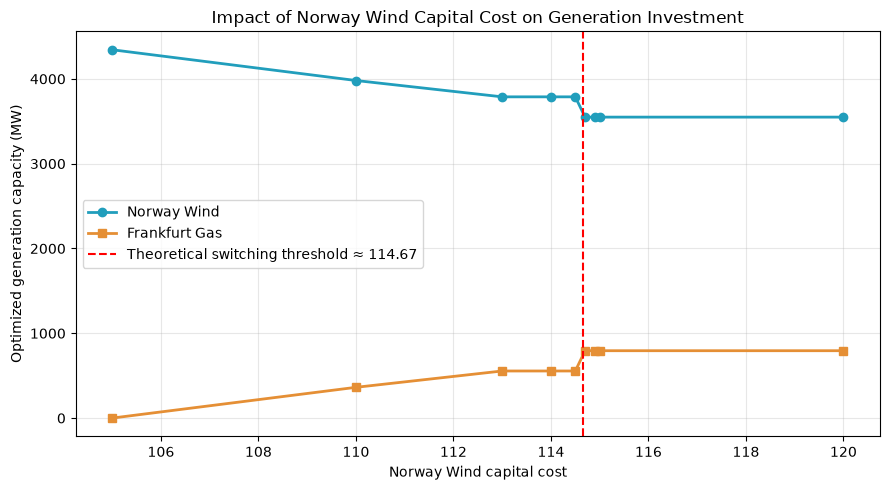

In [26]:
solver_threshold = threshold #pick up the threshold value above for plotting
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    cost_results["Norway Wind capital cost"],
    cost_results["Norway Wind (MW)"],
    marker="o",
    linewidth=2,
    color="#219EBC",
    label="Norway Wind"
)

ax.plot(
    cost_results["Norway Wind capital cost"],
    cost_results["Frankfurt Gas (MW)"],
    marker="s",
    linewidth=2,
    color="#E58F35",
    label="Frankfurt Gas"
)

# Threshold identified from the optimization results
ax.axvline(
    x=solver_threshold,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Theoretical switching threshold ≈ {solver_threshold:.2f}"
)

ax.set_xlabel("Norway Wind capital cost")
ax.set_ylabel("Optimized generation capacity (MW)")
ax.set_title("Impact of Norway Wind Capital Cost on Generation Investment")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../plots/wind_gas_investment_sensitivity.png", dpi=300)
plt.show()

As shown in the above figure, Norway Wind capacity begins to increase and Frankfurt Gas capacity begin to decreases when the wind capital cost falls below the theoretical threshold of aproximately 114.67.

#### References

Creti, A., & Fontini, F. (2019). *Economics of electricity: Markets, competition, and rules*. Cambridge University Press.

Kiehle, J., Lindroos, T. J., Louis, J.-N., & Pongrácz, E. (2026). Lost flexibility: Hydropower capabilities in large-scale, Pan-European energy system models. *Applied Energy, 423*, 128324. https://doi.org/10.1016/j.apenergy.2026.128324

Wang, J., & Noel, W. (2024). *Energy market restructuring: Pembina Institute comments and recommendations*. Pembina Institute. Submitted to the Alberta Electric System Operator.